# 03 - Machine Learning Modelling

## Objective

The purpose of this notebook is to develop machine learning models that identify the most important determinants of three key population health outcomes:

- Under-five mortality rate
- Maternal mortality ratio
- Life expectancy at birth

Rather than focusing solely on prediction accuracy, the models will be used to generate evidence for health policy decision-making. Feature importance from each model will later be combined to build a Global Health Policy Decision-Intelligence Framework that ranks health investment priorities.

This notebook includes:

- Data preparation
- Feature selection
- Model development
- Model evaluation
- Explainable Machine Learning (Feature Importance)

In [109]:
import pandas as pd
import numpy as np

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

In [110]:
wide = pd.read_csv("../data/clean/health_data_clean.csv")

In [111]:
wide.shape
wide.head()

,Country Name,Year,AIDS estimated deaths (UNAIDS estimates),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (0-14 years) living with HIV,Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old",Antiretroviral therapy coverage (% of people living with HIV),Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV),...,"Suicide mortality rate (per 100,000 population)","Total alcohol consumption per capita (liters of pure alcohol, projected estimates, 15+ years of age)",Treatment for hypertension (% of adults ages 30-79 with hypertension),"Tuberculosis case detection rate (%, all forms)","Tuberculosis death rate (per 100,000 people)",Tuberculosis treatment success rate (% of new cases),UHC service coverage index,"Unemployment, total (% of total labor force)",Urban population (% of total population),Vitamin A supplementation coverage rate (% of children ages 6-59 months)
0,Afghanistan,2000,100.0,154.310,1400.0,500.0,109.586048,4.740774,0.0,0.0,...,4.36,0.003,27.8,24.0,50.0,85.0,23.0,7.897,18.558200,58.0
1,Afghanistan,2001,100.0,152.471,1600.0,500.0,110.219341,4.755047,0.0,0.0,...,4.38,0.003,28.9,29.0,55.0,84.0,24.0,7.973,18.741238,76.0
2,Afghanistan,2002,100.0,150.161,1800.0,500.0,110.534611,4.766449,0.0,0.0,...,4.26,0.007,30.0,33.0,59.0,87.0,25.0,7.867,18.941248,94.0
3,Afghanistan,2003,200.0,143.750,2000.0,500.0,110.557540,4.772819,0.0,0.0,...,4.24,0.016,31.1,28.0,68.0,86.0,26.0,7.844,19.160035,71.0
4,Afghanistan,2004,200.0,136.930,2200.0,500.0,110.285308,4.770631,0.0,0.0,...,4.23,0.021,32.2,34.0,67.0,89.0,27.0,7.794,19.399359,95.0


In [112]:
targets = [
    "Mortality rate, under-5 (per 1,000)",
    "Maternal mortality ratio (modeled estimate, per 100,000 live births)",
    "Life expectancy at birth, total (years)"
]

In [113]:
outcome_vars = [
    "Mortality rate, infant (per 1,000 live births)",
    "Mortality rate, neonatal (per 1,000 live births)",
    "Number of infant deaths",
    "Number of neonatal deaths",
    "Number of under-five deaths",
    "Number of maternal deaths",
    "Stillbirth rate (per 1,000 total births)",
    "Number of stillbirths",
    "Death rate, crude (per 1,000 people)",
    "Lifetime risk of maternal death (%)",
    "Mortality caused by road traffic injury (per 100,000 people)",
    "Mortality from CVD, cancer, diabetes or CRD between exact ages 30 and 70 (%)",
    "Mortality rate attributed to unintentional poisoning (per 100,000 population)",
    "Suicide mortality rate (per 100,000 population)",
    "Tuberculosis death rate (per 100,000 people)",
    "Cause of death, by communicable diseases and maternal, prenatal and nutrition conditions (% of total)",
    "Cause of death, by injury (% of total)",
    "Cause of death, by non-communicable diseases (% of total)",
    "Cause of death, by other COVID-19 pandemic-related outcomes (% of total)"
]

In [114]:
X = wide.drop(columns=targets + outcome_vars, errors="ignore")

In [115]:
y_u5 = wide[targets[0]]

y_maternal = wide[targets[1]]

y_life = wide[targets[2]]

In [116]:
print(X.shape)
X.head()

(575, 76)


,Country Name,Year,AIDS estimated deaths (UNAIDS estimates),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (0-14 years) living with HIV,Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old",Antiretroviral therapy coverage (% of people living with HIV),Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV),...,"School enrollment, secondary (% net)","School enrollment, tertiary (% gross)","Total alcohol consumption per capita (liters of pure alcohol, projected estimates, 15+ years of age)",Treatment for hypertension (% of adults ages 30-79 with hypertension),"Tuberculosis case detection rate (%, all forms)",Tuberculosis treatment success rate (% of new cases),UHC service coverage index,"Unemployment, total (% of total labor force)",Urban population (% of total population),Vitamin A supplementation coverage rate (% of children ages 6-59 months)
0,Afghanistan,2000,100.0,154.310,1400.0,500.0,109.586048,4.740774,0.0,0.0,...,26.55995,1.37435,0.003,27.8,24.0,85.0,23.0,7.897,18.558200,58.0
1,Afghanistan,2001,100.0,152.471,1600.0,500.0,110.219341,4.755047,0.0,0.0,...,26.55995,1.37435,0.003,28.9,29.0,84.0,24.0,7.973,18.741238,76.0
2,Afghanistan,2002,100.0,150.161,1800.0,500.0,110.534611,4.766449,0.0,0.0,...,26.55995,1.37435,0.007,30.0,33.0,87.0,25.0,7.867,18.941248,94.0
3,Afghanistan,2003,200.0,143.750,2000.0,500.0,110.557540,4.772819,0.0,0.0,...,26.55995,1.37435,0.016,31.1,28.0,86.0,26.0,7.844,19.160035,71.0
4,Afghanistan,2004,200.0,136.930,2200.0,500.0,110.285308,4.770631,0.0,0.0,...,26.55995,1.39064,0.021,32.2,34.0,89.0,27.0,7.794,19.399359,95.0


In [117]:
X.isnull().sum().sum()

np.int64(0)

In [118]:
set(outcome_vars).intersection(X.columns)

set()

In [119]:
set(targets).intersection(X.columns)

set()

In [120]:
X = X.drop(columns=["Country Name"])

In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_u5,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(460, 75)
(115, 75)


In [122]:
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [123]:
pred = rf.predict(X_test)

In [124]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("R²  :", round(r2,3))

MAE : 10.91
RMSE: 31.51
R²  : 0.716


In [125]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": pred
})

results.head(10)

,Actual,Predicted
153,46.4,47.5368
118,165.9,157.6460
245,93.2,93.6342
408,117.0,109.6872
278,143.2,137.0030
185,169.3,178.0372
234,144.8,161.1818
29,144.4,147.3794
82,134.2,238.3580
158,39.1,40.3276


In [126]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
71,UHC service coverage index,0.567743
43,Population growth (annual %),0.075768
24,"Immunization, DPT (% of children ages 12-23 mo...",0.048334
46,Prevalence of anemia among children (% of chil...,0.037255
2,"Adolescent fertility rate (births per 1,000 wo...",0.027180
47,Prevalence of anemia among pregnant women (%),0.023983
21,"Fertility rate, total (births per woman)",0.022844
55,Prevalence of syphilis (% of women attending a...,0.015918
48,Prevalence of anemia among women of reproducti...,0.014864
26,"Incidence of malaria (per 1,000 population at ...",0.014063


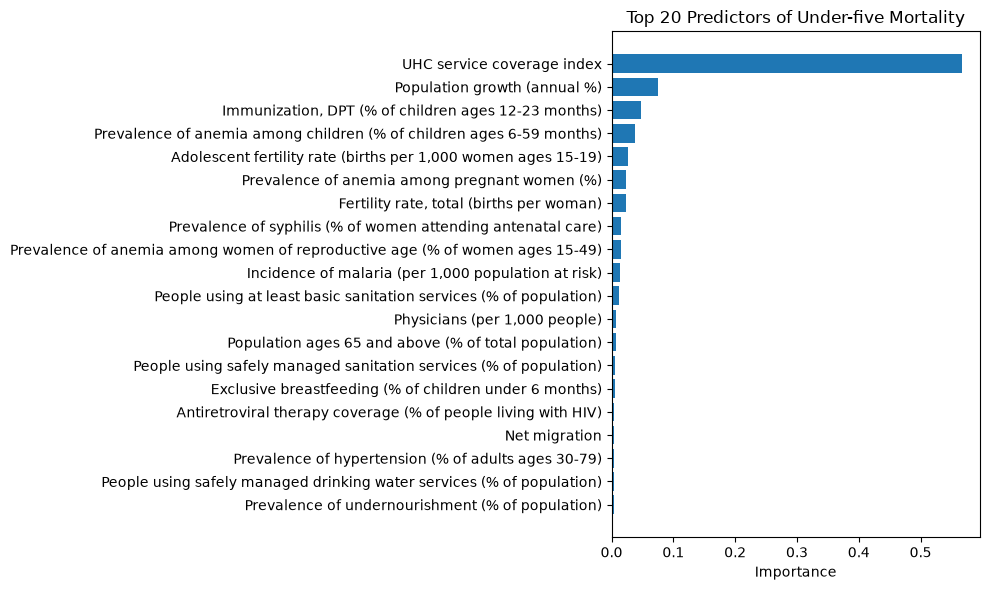

In [127]:
top20 = importance.head(20)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title("Top 20 Predictors of Under-five Mortality")

plt.tight_layout()
plt.show()

In [128]:
from sklearn.model_selection import GridSearchCV

In [129]:
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [130]:
grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [200, 500]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [131]:
grid.best_params_

{'max_depth': 20,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 200}

In [132]:
grid.best_score_

np.float64(0.8701553105410336)

In [133]:
best_rf = grid.best_estimator_

In [134]:
pred_best = best_rf.predict(X_test)

In [135]:
mae = mean_absolute_error(y_test, pred_best)
rmse = np.sqrt(mean_squared_error(y_test, pred_best))
r2 = r2_score(y_test, pred_best)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 10.97
RMSE: 31.56
R²  : 0.715


In [136]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
71,UHC service coverage index,0.567366
43,Population growth (annual %),0.079419
24,"Immunization, DPT (% of children ages 12-23 mo...",0.045364
46,Prevalence of anemia among children (% of chil...,0.037370
2,"Adolescent fertility rate (births per 1,000 wo...",0.028416
47,Prevalence of anemia among pregnant women (%),0.024145
21,"Fertility rate, total (births per woman)",0.023627
48,Prevalence of anemia among women of reproducti...,0.014555
26,"Incidence of malaria (per 1,000 population at ...",0.012108
36,People using at least basic sanitation service...,0.011699


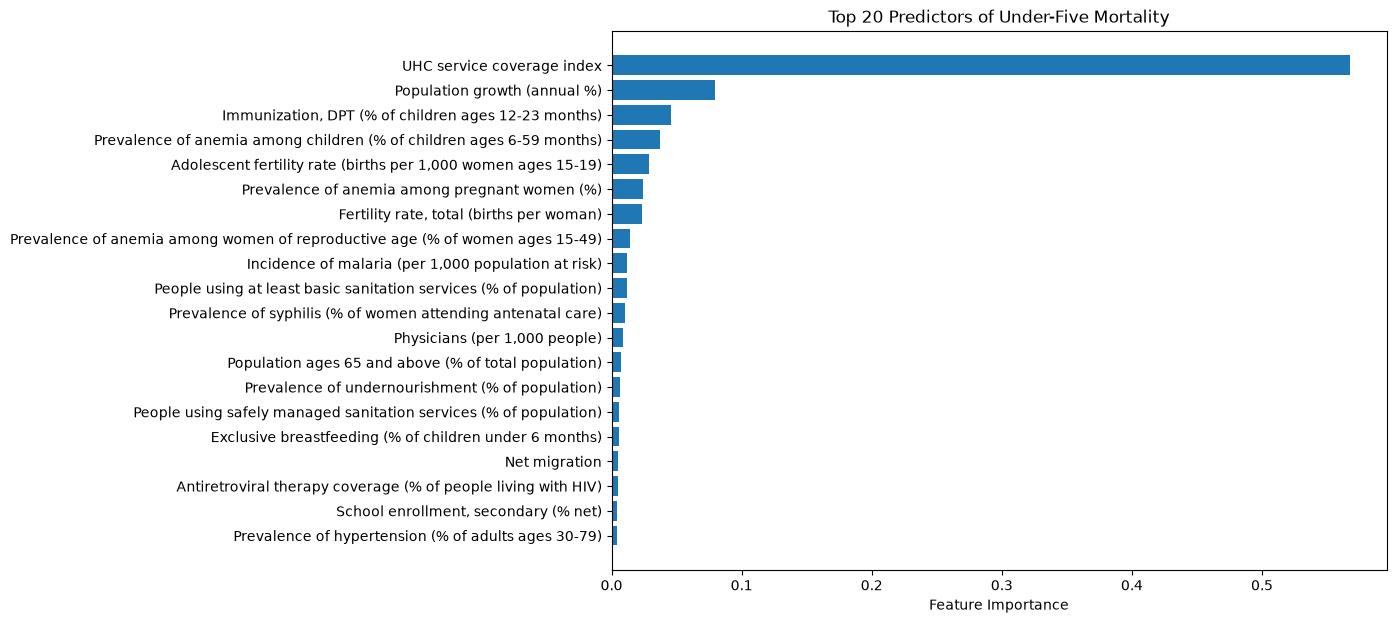

In [137]:
top20 = importance.head(20)

plt.figure(figsize=(10,7))

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.title("Top 20 Predictors of Under-Five Mortality")

plt.show()

In [138]:
xgb = XGBRegressor(
    random_state=42
)

xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [139]:
y_pred_xgb = xgb.predict(X_test)

In [140]:
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 12.61
RMSE: 36.34
R²  : 0.622


In [141]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_xgb
})

comparison.head(10)

,Actual,Predicted
153,46.4,47.987652
118,165.9,166.238266
245,93.2,95.261490
408,117.0,114.750832
278,143.2,145.065842
185,169.3,152.790649
234,144.8,149.884766
29,144.4,157.411743
82,134.2,328.099304
158,39.1,38.893124


In [142]:
importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
})

importance_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

importance_xgb.head(20)

,Feature,Importance
71,UHC service coverage index,0.429865
24,"Immunization, DPT (% of children ages 12-23 mo...",0.098747
48,Prevalence of anemia among women of reproducti...,0.058722
43,Population growth (annual %),0.054329
46,Prevalence of anemia among children (% of chil...,0.050064
37,People using safely managed drinking water ser...,0.035629
47,Prevalence of anemia among pregnant women (%),0.034447
21,"Fertility rate, total (births per woman)",0.033500
67,Total alcohol consumption per capita (liters o...,0.018219
2,"Adolescent fertility rate (births per 1,000 wo...",0.015728


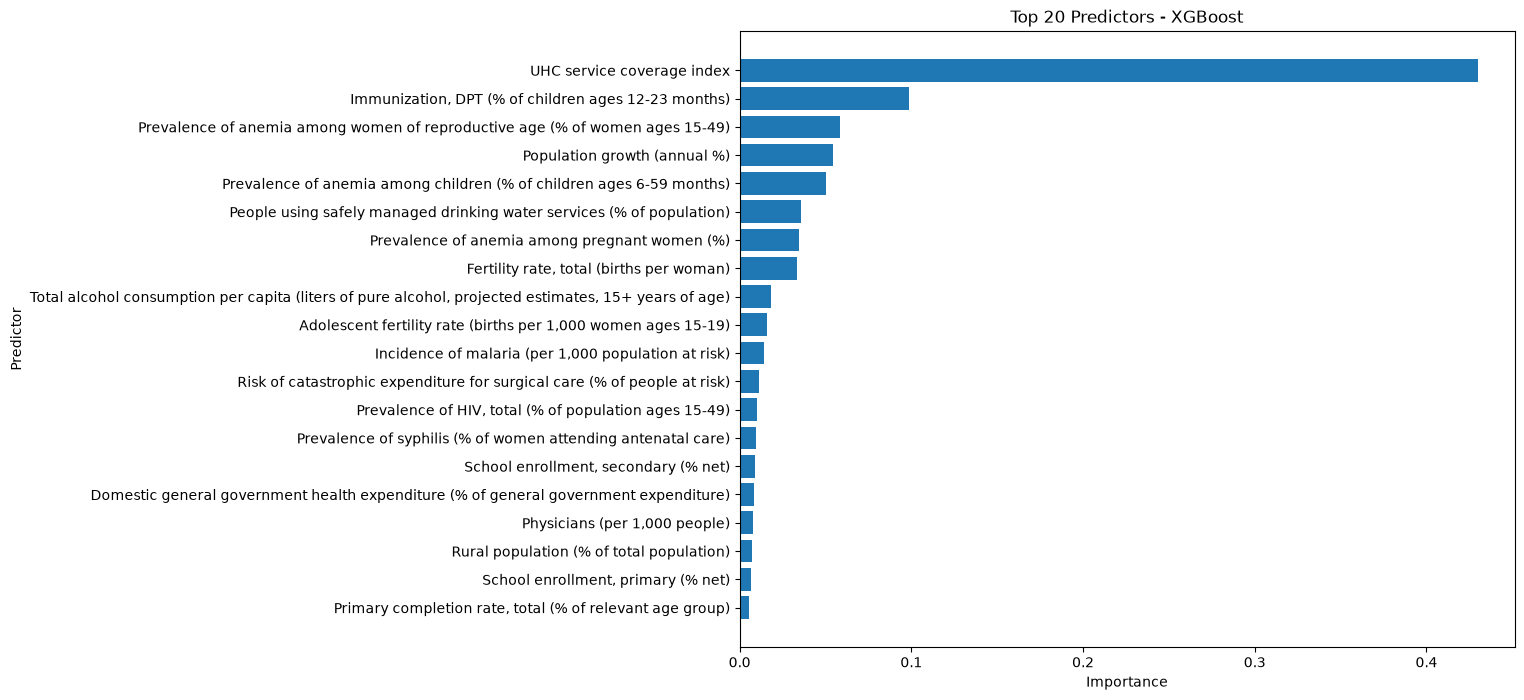

In [143]:
top20 = importance_xgb.head(20)

plt.figure(figsize=(10,8))
plt.barh(top20["Feature"], top20["Importance"])
plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Predictor")
plt.title("Top 20 Predictors - XGBoost")

plt.show()

In [144]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42
)

In [145]:
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1],
    "subsample": [0.8, 1.0]
}

In [146]:
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.1], 'max_depth': [3, 5, ...], 'n_estimators': [100, 300, ...], 'subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [147]:
print(grid_xgb.best_params_)
print(grid_xgb.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500, 'subsample': 1.0}
0.8871851191083738


In [148]:
xgb_best = grid_xgb.best_estimator_

In [149]:
y_pred_xgb = xgb_best.predict(X_test)

In [150]:
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 12.82
RMSE: 38.52
R²  : 0.575


In [151]:
importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_best.feature_importances_
})

importance_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

importance_xgb.head(20)

,Feature,Importance
71,UHC service coverage index,0.245230
21,"Fertility rate, total (births per woman)",0.123381
46,Prevalence of anemia among children (% of chil...,0.083482
43,Population growth (annual %),0.057782
24,"Immunization, DPT (% of children ages 12-23 mo...",0.050077
60,"Public spending on education, total (% of GDP)",0.044794
40,"Physicians (per 1,000 people)",0.043658
47,Prevalence of anemia among pregnant women (%),0.030059
36,People using at least basic sanitation service...,0.026732
26,"Incidence of malaria (per 1,000 population at ...",0.025412


In [152]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [10.97, 12.82],
    "RMSE": [31.56, 38.52],
    "R²": [0.715, 0.575]
})

comparison

,Model,MAE,RMSE,R²
0,Random Forest,10.97,31.56,0.715
1,XGBoost,12.82,38.52,0.575


In [153]:
import shap

In [154]:
explainer = shap.TreeExplainer(best_rf)

In [155]:
shap_values = explainer.shap_values(X_test)

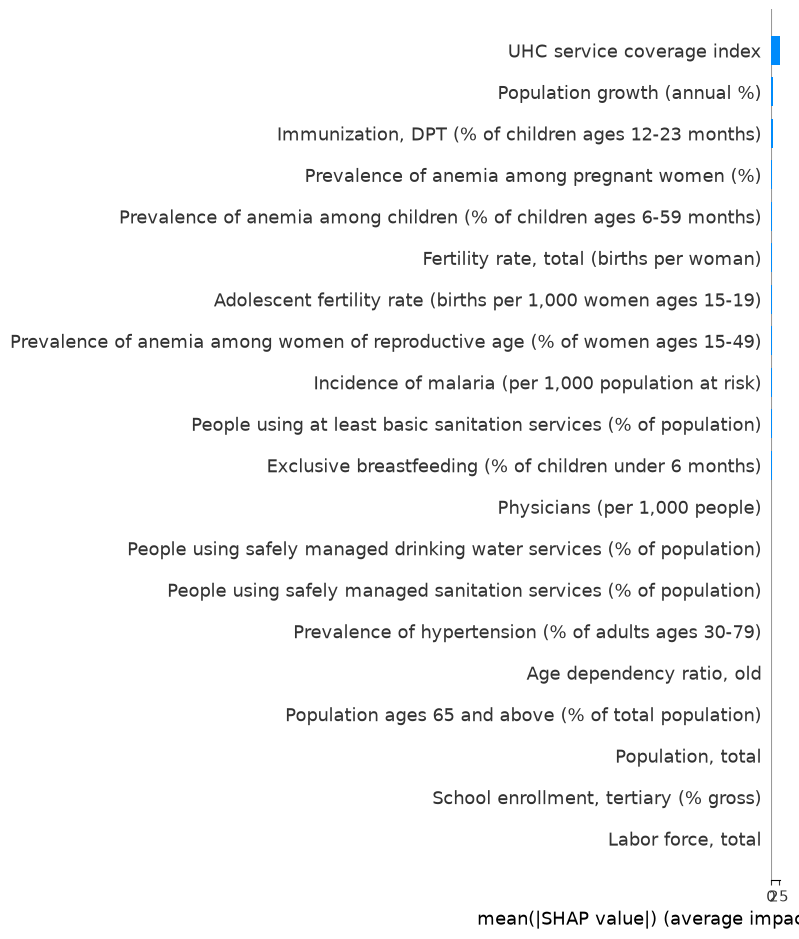

c:\Users\786\Desktop\document\Global Health Policy Decision Intelligence\venv\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


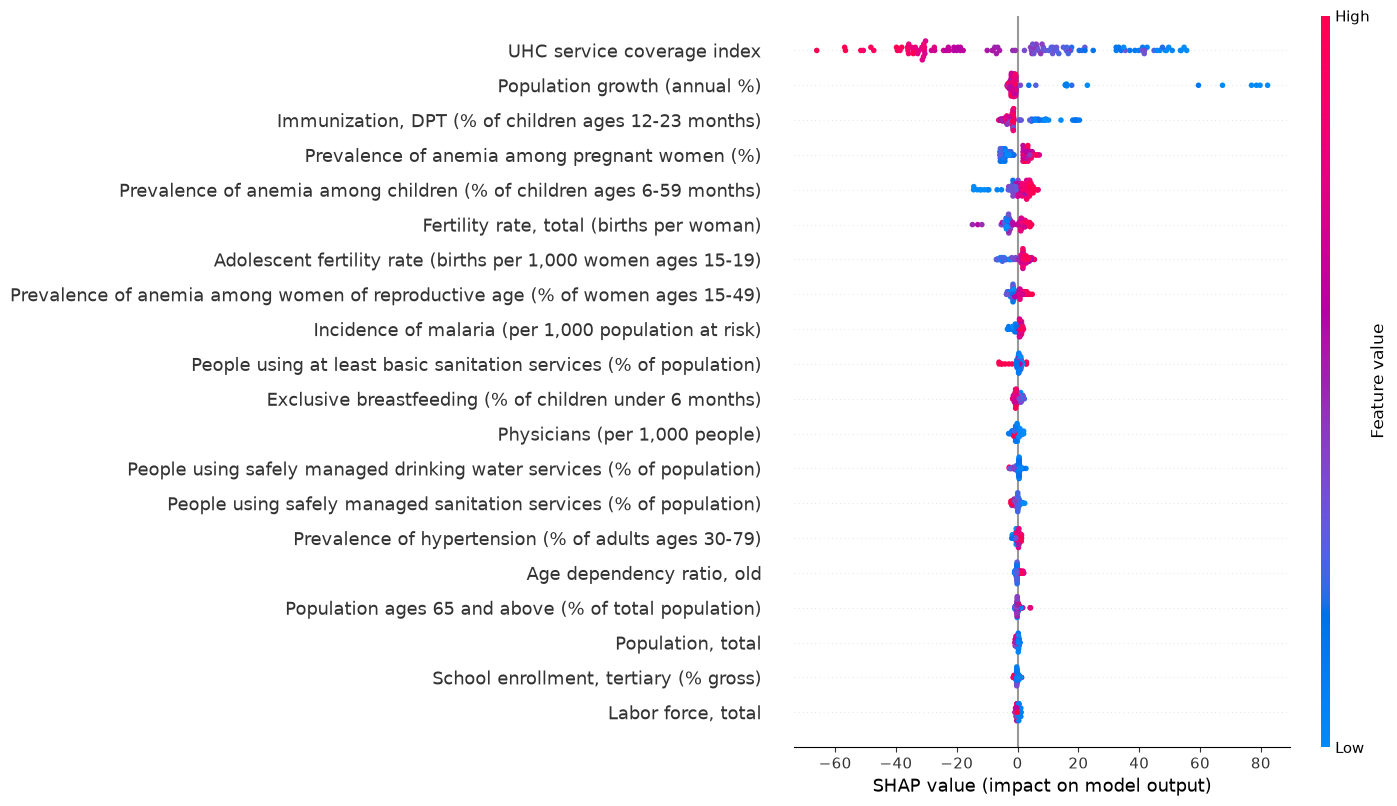

In [156]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20
)

shap.summary_plot(
    shap_values,
    X_test,
    max_display=20
)

In [157]:
shap_u5 = pd.DataFrame({
    "Feature": X.columns,
    "SHAP Importance": np.abs(shap_values).mean(axis=0)
})

shap_u5 = shap_u5.sort_values(
    by="SHAP Importance",
    ascending=False
)

shap_u5.head(20)

,Feature,SHAP Importance
71,UHC service coverage index,26.746011
43,Population growth (annual %),6.491806
24,"Immunization, DPT (% of children ages 12-23 mo...",4.305478
47,Prevalence of anemia among pregnant women (%),3.712085
46,Prevalence of anemia among children (% of chil...,3.098808
21,"Fertility rate, total (births per woman)",2.822933
2,"Adolescent fertility rate (births per 1,000 wo...",2.752788
48,Prevalence of anemia among women of reproducti...,1.663071
26,"Incidence of malaria (per 1,000 population at ...",0.946999
36,People using at least basic sanitation service...,0.867559


In [158]:
shap_u5.to_csv("../models/shap_u5.csv", index=False)

In [159]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_maternal,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(460, 75)
(115, 75)


In [160]:
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

rf.fit(X_train, y_train)

pred = rf.predict(X_test)

In [161]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("R²  :", round(r2,3))

MAE : 50.83
RMSE: 77.48
R²  : 0.964


In [162]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": pred
})

results.head(10)

,Actual,Predicted
153,413.0,404.474
118,605.0,643.152
245,784.0,730.044
408,578.0,541.704
278,404.0,469.136
185,1222.0,1003.554
234,645.0,791.026
29,463.0,478.214
82,1092.0,1076.134
158,334.0,349.526


In [163]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
71,UHC service coverage index,0.203698
24,"Immunization, DPT (% of children ages 12-23 mo...",0.190384
9,Births attended by skilled health staff (% of ...,0.097850
36,People using at least basic sanitation service...,0.091455
15,Domestic general government health expenditure...,0.038107
60,"Public spending on education, total (% of GDP)",0.027792
44,"Population, total",0.025642
37,People using safely managed drinking water ser...,0.023302
50,Prevalence of hypertension (% of adults ages 3...,0.022481
27,"Incidence of tuberculosis (per 100,000 people)",0.015744


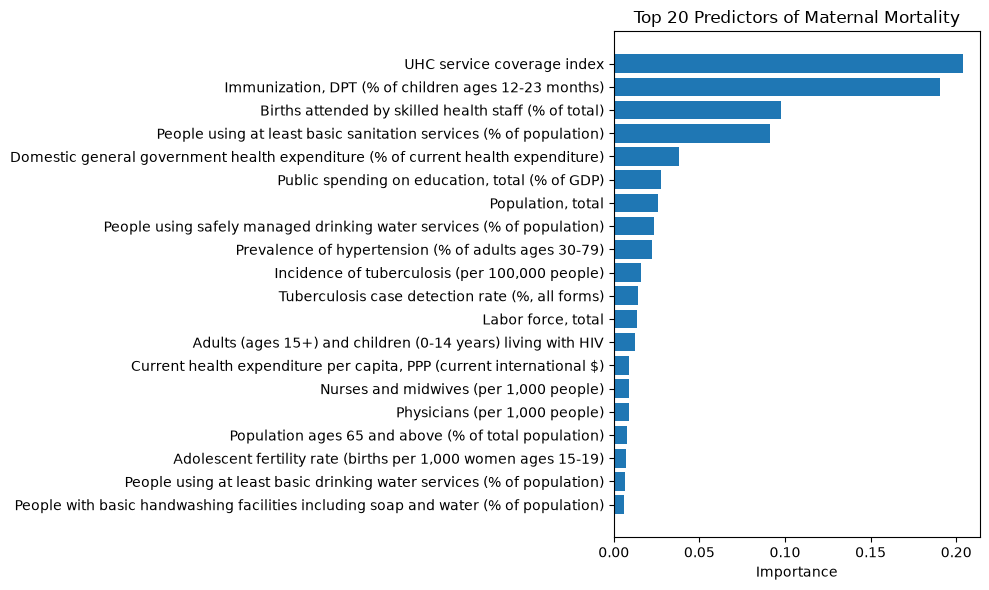

In [164]:
top20 = importance.head(20)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title("Top 20 Predictors of Maternal Mortality")

plt.tight_layout()
plt.show()


In [165]:
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [200, 500]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [166]:
grid.best_params_

{'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 500}

In [167]:
best_rf = grid.best_estimator_

pred_best = best_rf.predict(X_test)

In [168]:
mae = mean_absolute_error(y_test, pred_best)
rmse = np.sqrt(mean_squared_error(y_test, pred_best))
r2 = r2_score(y_test, pred_best)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 51.46
RMSE: 78.48
R²  : 0.963


In [169]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
71,UHC service coverage index,0.203738
24,"Immunization, DPT (% of children ages 12-23 mo...",0.190709
9,Births attended by skilled health staff (% of ...,0.097984
36,People using at least basic sanitation service...,0.091594
15,Domestic general government health expenditure...,0.038165
60,"Public spending on education, total (% of GDP)",0.027868
44,"Population, total",0.025383
37,People using safely managed drinking water ser...,0.023348
50,Prevalence of hypertension (% of adults ages 3...,0.022207
27,"Incidence of tuberculosis (per 100,000 people)",0.015894


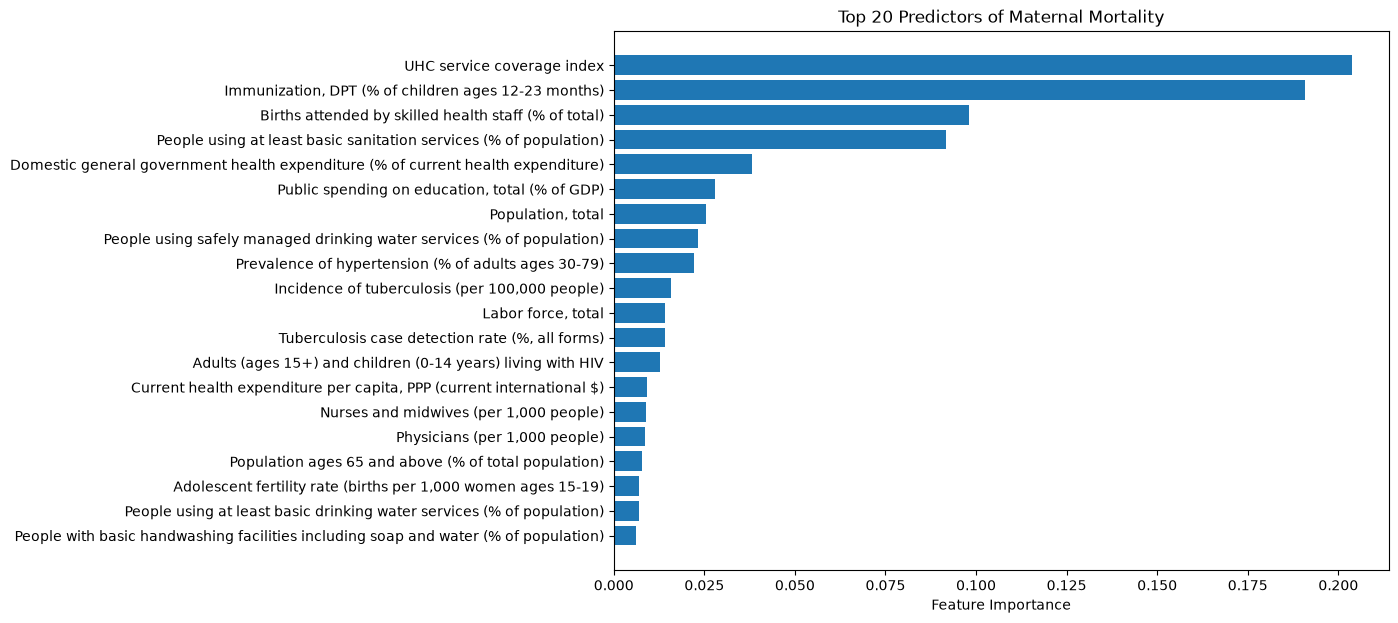

In [170]:
top20 = importance.head(20)

plt.figure(figsize=(10,7))

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.title("Top 20 Predictors of Maternal Mortality")

plt.show()

In [171]:
xgb = XGBRegressor(
    random_state=42
)

xgb.fit(X_train, y_train)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [172]:
y_pred_xgb = xgb.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 49.06
RMSE: 83.41
R²  : 0.958


In [173]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_xgb
})

comparison.head(10)

,Actual,Predicted
153,413.0,383.812073
118,605.0,601.363464
245,784.0,776.601562
408,578.0,465.928375
278,404.0,443.874512
185,1222.0,1016.075623
234,645.0,748.022949
29,463.0,529.359436
82,1092.0,1177.722778
158,334.0,359.837585


In [174]:
importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
})

importance_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

importance_xgb.head(20)

,Feature,Importance
71,UHC service coverage index,0.266754
36,People using at least basic sanitation service...,0.164772
24,"Immunization, DPT (% of children ages 12-23 mo...",0.119773
44,"Population, total",0.086421
50,Prevalence of hypertension (% of adults ages 3...,0.039772
9,Births attended by skilled health staff (% of ...,0.037077
66,"School enrollment, tertiary (% gross)",0.031778
3,Adults (ages 15+) and children (0-14 years) li...,0.017466
23,"Hospital beds (per 1,000 people)",0.015914
69,"Tuberculosis case detection rate (%, all forms)",0.015479


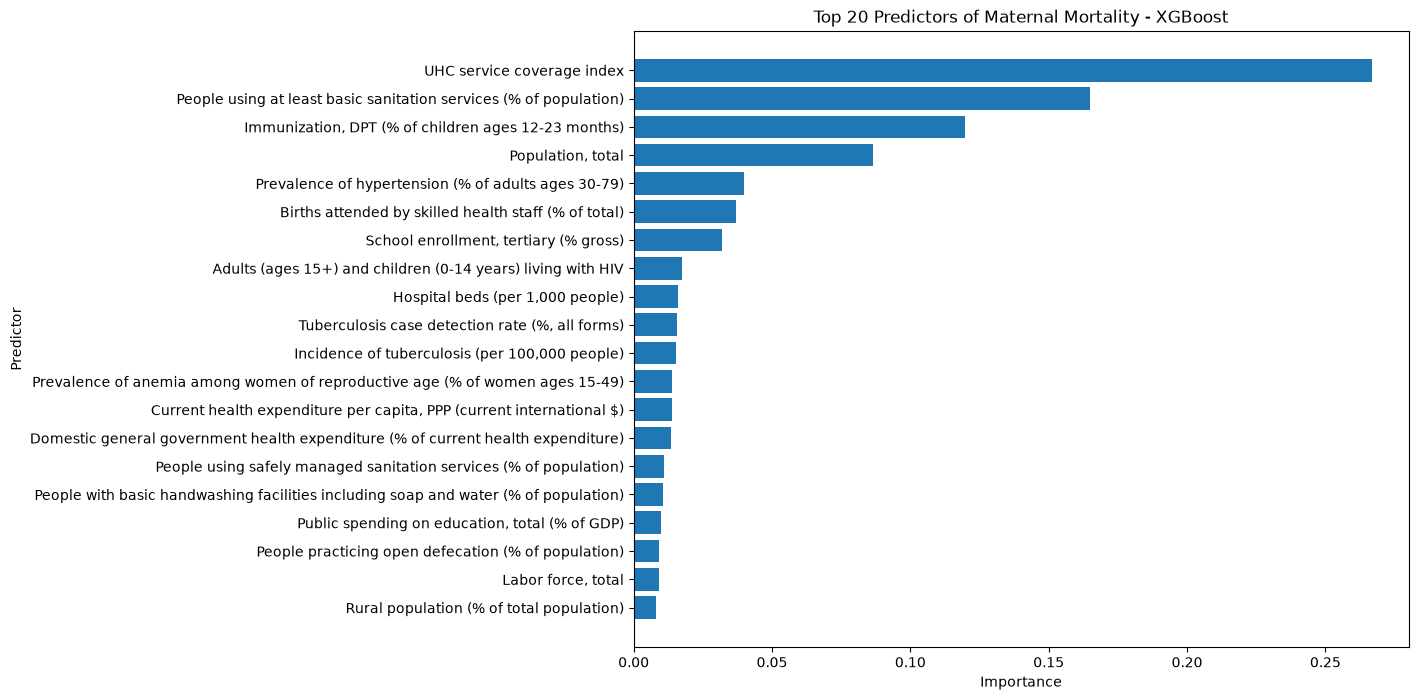

In [175]:
top20 = importance_xgb.head(20)

plt.figure(figsize=(10,8))
plt.barh(top20["Feature"], top20["Importance"])
plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Predictor")
plt.title("Top 20 Predictors of Maternal Mortality - XGBoost")

plt.show()

In [176]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42
)

In [177]:
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1],
    "subsample": [0.8, 1.0]
}

In [178]:
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.1], 'max_depth': [3, 5, ...], 'n_estimators': [100, 300, ...], 'subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [179]:
print(grid_xgb.best_params_)
print(grid_xgb.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8}
0.943349327940186


In [180]:
xgb_best = grid_xgb.best_estimator_

y_pred_xgb = xgb_best.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 40.24
RMSE: 61.04
R²  : 0.978


In [181]:
importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_best.feature_importances_
})

importance_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

importance_xgb.head(20)

,Feature,Importance
71,UHC service coverage index,0.182618
9,Births attended by skilled health staff (% of ...,0.087235
24,"Immunization, DPT (% of children ages 12-23 mo...",0.079996
36,People using at least basic sanitation service...,0.064901
44,"Population, total",0.057971
50,Prevalence of hypertension (% of adults ages 3...,0.056380
37,People using safely managed drinking water ser...,0.040751
3,Adults (ages 15+) and children (0-14 years) li...,0.035408
39,People with basic handwashing facilities inclu...,0.031436
66,"School enrollment, tertiary (% gross)",0.021759


In [182]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [51.46, 40.24],
    "RMSE": [78.48, 61.04],
    "R²": [0.963, 0.978]
})

comparison

,Model,MAE,RMSE,R²
0,Random Forest,51.46,78.48,0.963
1,XGBoost,40.24,61.04,0.978


In [183]:
explainer = shap.TreeExplainer(xgb_best)

c:\Users\786\Desktop\document\Global Health Policy Decision Intelligence\venv\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


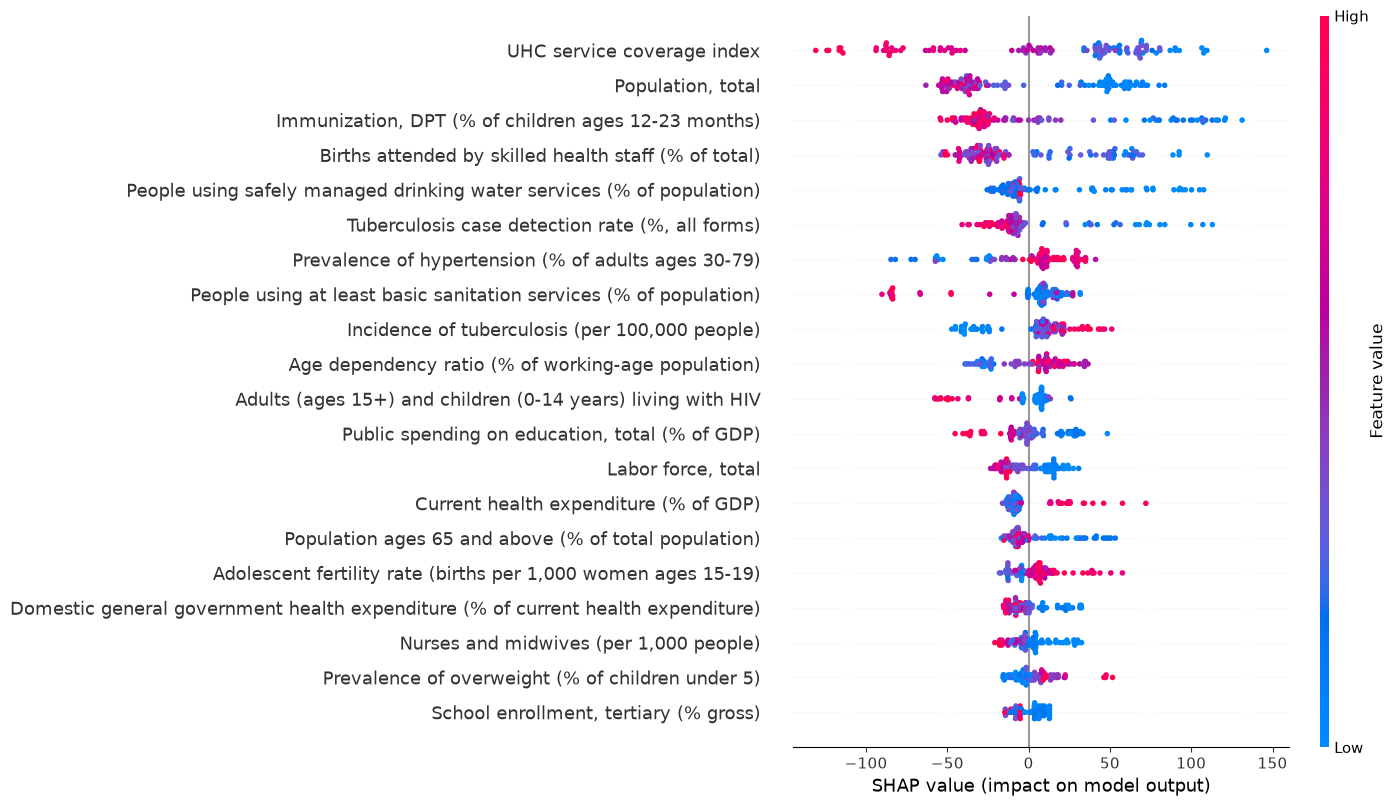

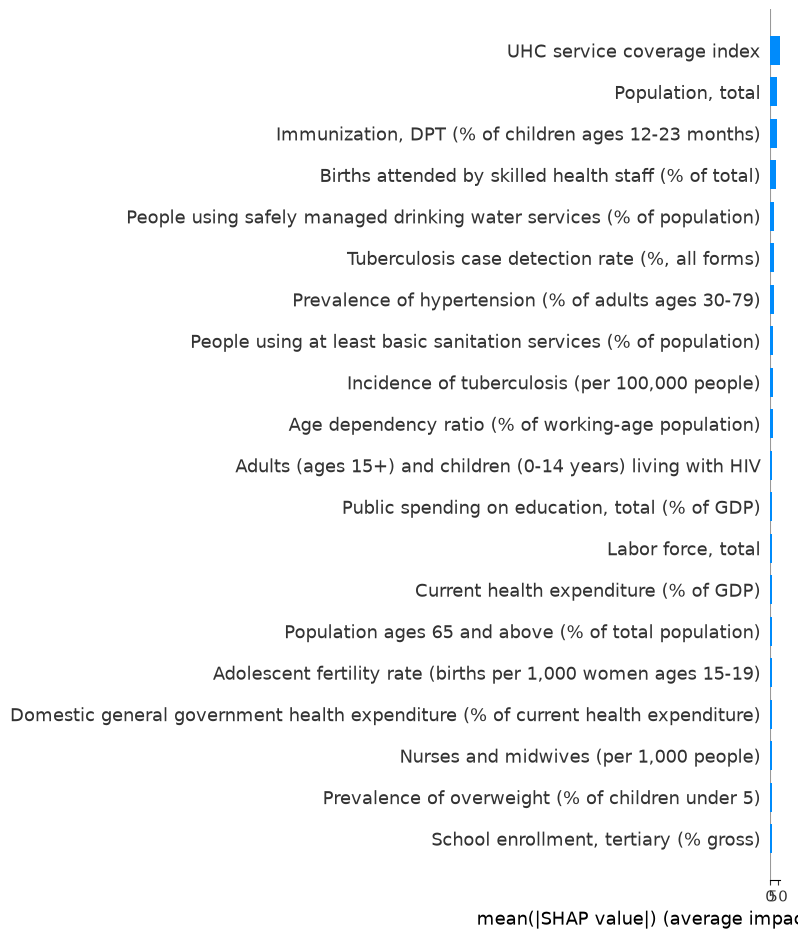

In [184]:
shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test,
    max_display=20
)


shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20
)

In [185]:
shap_maternal = pd.DataFrame({
    "Feature": X.columns,
    "SHAP Importance": np.abs(shap_values).mean(axis=0)
})

shap_maternal = shap_maternal.sort_values(
    by="SHAP Importance",
    ascending=False
)

shap_maternal.head(20)

,Feature,SHAP Importance
71,UHC service coverage index,58.385860
44,"Population, total",43.563976
24,"Immunization, DPT (% of children ages 12-23 mo...",42.702930
9,Births attended by skilled health staff (% of ...,36.545921
37,People using safely managed drinking water ser...,23.354317
69,"Tuberculosis case detection rate (%, all forms)",21.608454
50,Prevalence of hypertension (% of adults ages 3...,20.295799
36,People using at least basic sanitation service...,20.078299
27,"Incidence of tuberculosis (per 100,000 people)",19.379183
5,Age dependency ratio (% of working-age populat...,18.256512


In [186]:
shap_maternal.to_csv("../models/shap_maternal.csv", index=False)

In [187]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_life,
    test_size=0.20,
    random_state=42
)

In [188]:
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [189]:
pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("R²  :", round(r2,3))

MAE : 1.38
RMSE: 3.27
R²  : 0.843


In [190]:
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [200, 500]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [191]:
grid.best_params_

{'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 500}

In [192]:
best_rf = grid.best_estimator_

pred_best = best_rf.predict(X_test)

mae = mean_absolute_error(y_test, pred_best)
rmse = np.sqrt(mean_squared_error(y_test, pred_best))
r2 = r2_score(y_test, pred_best)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 1.38
RMSE: 3.26
R²  : 0.843


In [193]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
71,UHC service coverage index,0.546814
43,Population growth (annual %),0.067168
36,People using at least basic sanitation service...,0.066219
40,"Physicians (per 1,000 people)",0.046019
46,Prevalence of anemia among children (% of chil...,0.028567
24,"Immunization, DPT (% of children ages 12-23 mo...",0.028216
37,People using safely managed drinking water ser...,0.021408
26,"Incidence of malaria (per 1,000 population at ...",0.020092
55,Prevalence of syphilis (% of women attending a...,0.010436
21,"Fertility rate, total (births per woman)",0.009294


In [194]:
xgb = XGBRegressor(
    random_state=42
)

xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [195]:
y_pred_xgb = xgb.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 1.54
RMSE: 3.86
R²  : 0.780


In [196]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42
)

param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1],
    "subsample": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.1], 'max_depth': [3, 5, ...], 'n_estimators': [100, 300, ...], 'subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [197]:
print(grid_xgb.best_params_)
print(grid_xgb.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500, 'subsample': 1.0}
0.9247281067071412


In [198]:
xgb_best = grid_xgb.best_estimator_

y_pred_xgb = xgb_best.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

MAE : 1.74
RMSE: 4.71
R²  : 0.674


In [199]:
importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_best.feature_importances_
})

importance_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

importance_xgb.head(20)

,Feature,Importance
71,UHC service coverage index,0.284943
36,People using at least basic sanitation service...,0.132977
25,"Incidence of HIV, all (per 1,000 uninfected po...",0.075522
40,"Physicians (per 1,000 people)",0.064695
24,"Immunization, DPT (% of children ages 12-23 mo...",0.061495
21,"Fertility rate, total (births per woman)",0.050176
37,People using safely managed drinking water ser...,0.048126
43,Population growth (annual %),0.031043
26,"Incidence of malaria (per 1,000 population at ...",0.027677
64,"School enrollment, primary (% net)",0.027361


In [200]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [1.38, 1.74],
    "RMSE": [3.26, 4.71],
    "R²": [0.843, 0.674]
})

comparison

,Model,MAE,RMSE,R²
0,Random Forest,1.38,3.26,0.843
1,XGBoost,1.74,4.71,0.674


In [201]:
explainer = shap.TreeExplainer(best_rf)

shap_values = explainer.shap_values(X_test)

c:\Users\786\Desktop\document\Global Health Policy Decision Intelligence\venv\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


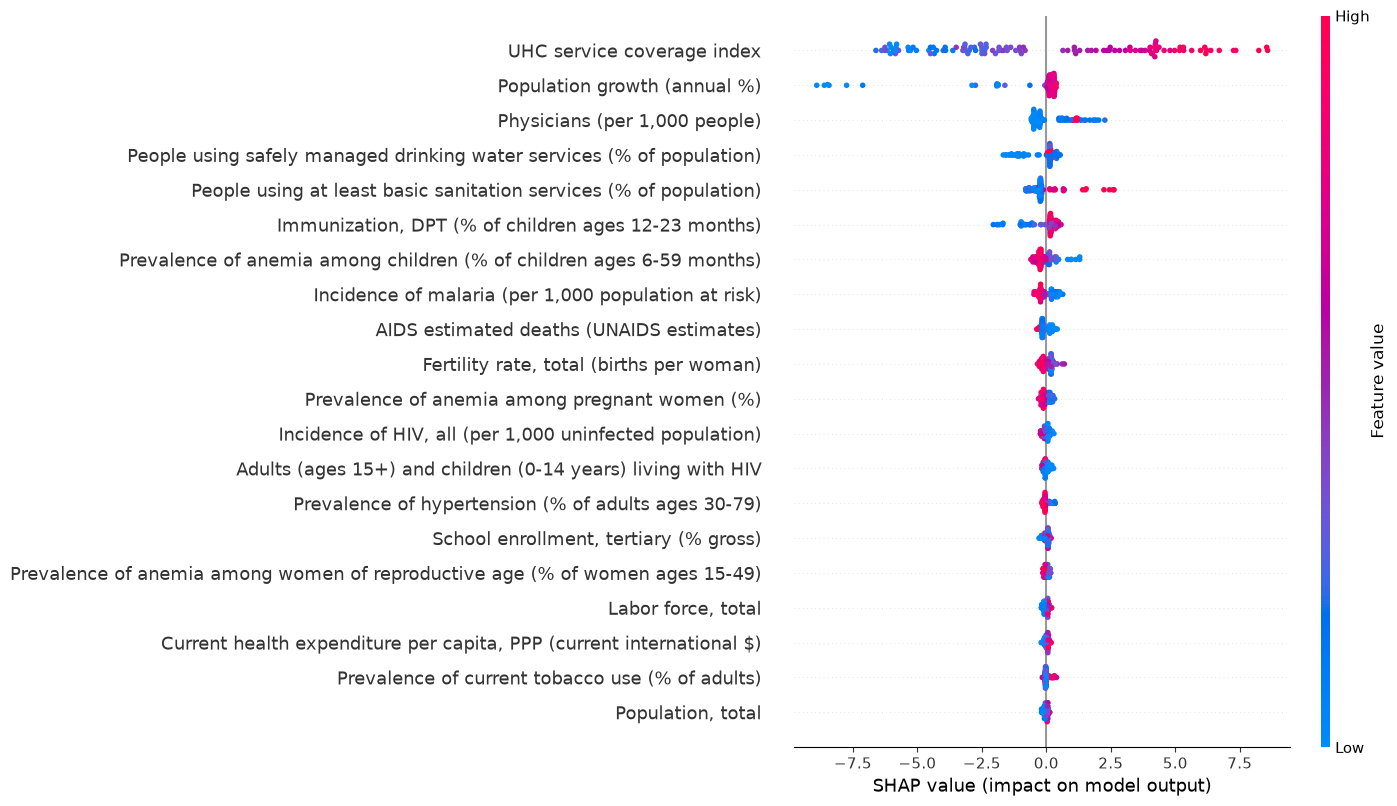

In [202]:
shap.summary_plot(
    shap_values,
    X_test,
    max_display=20
)

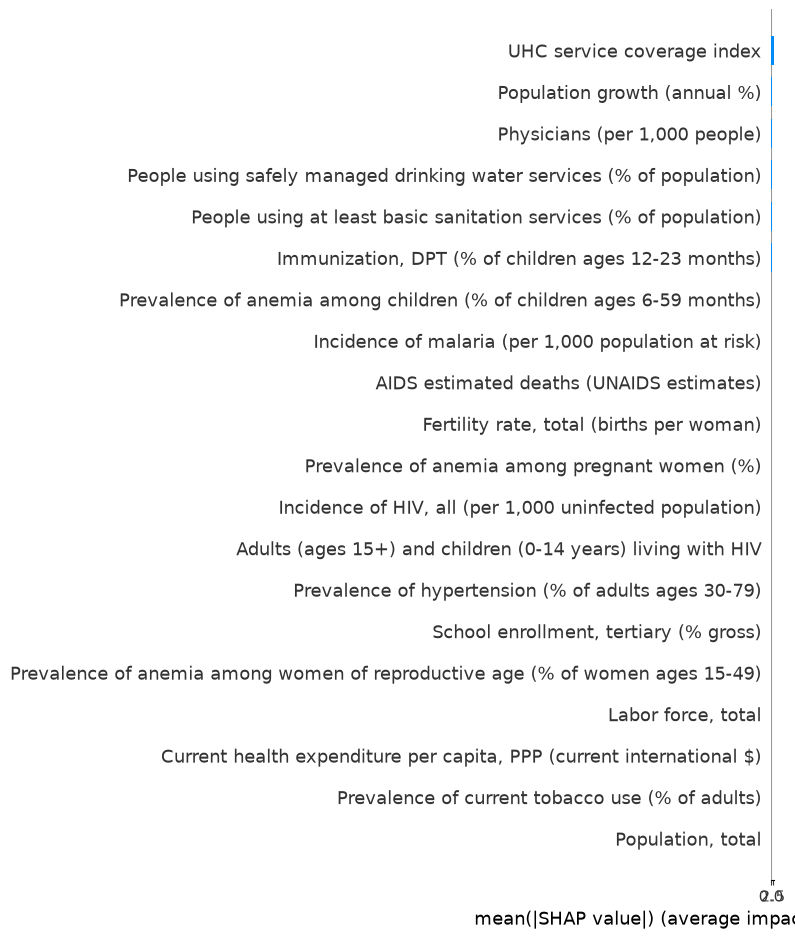

In [203]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20
)

In [204]:
shap_life = pd.DataFrame({
    "Feature": X.columns,
    "SHAP Importance": np.abs(shap_values).mean(axis=0)
})

shap_life = shap_life.sort_values(
    by="SHAP Importance",
    ascending=False
)

shap_life.head(20)

,Feature,SHAP Importance
71,UHC service coverage index,3.851429
43,Population growth (annual %),0.765985
40,"Physicians (per 1,000 people)",0.591989
37,People using safely managed drinking water ser...,0.470521
36,People using at least basic sanitation service...,0.466145
24,"Immunization, DPT (% of children ages 12-23 mo...",0.436257
46,Prevalence of anemia among children (% of chil...,0.285764
26,"Incidence of malaria (per 1,000 population at ...",0.256447
1,AIDS estimated deaths (UNAIDS estimates),0.182451
21,"Fertility rate, total (births per woman)",0.171907


In [205]:
shap_life.to_csv("../models/shap_life.csv", index=False)

In [3]:
import pandas as pd
model_performance = pd.DataFrame({
    "Outcome": [
        "Under-five Mortality",
        "Under-five Mortality",
        "Maternal Mortality",
        "Maternal Mortality",
        "Life Expectancy",
        "Life Expectancy"
    ],
    "Model": [
        "Random Forest",
        "XGBoost",
        "Random Forest",
        "XGBoost",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        10.97,
        12.82,
        51.46,
        40.24,
        1.38,
        1.74
    ],
    "RMSE": [
        31.56,
        38.52,
        78.48,
        61.04,
        3.26,
        4.71
    ],
    "R2": [
        0.715,
        0.575,
        0.963,
        0.978,
        0.843,
        0.674
    ]
})

model_performance["Selected"] = [
    "Yes", "No",
    "No", "Yes",
    "Yes", "No"
]

model_performance

,Outcome,Model,MAE,RMSE,R2,Selected
0,Under-five Mortality,Random Forest,10.97,31.56,0.715,Yes
1,Under-five Mortality,XGBoost,12.82,38.52,0.575,No
2,Maternal Mortality,Random Forest,51.46,78.48,0.963,No
3,Maternal Mortality,XGBoost,40.24,61.04,0.978,Yes
4,Life Expectancy,Random Forest,1.38,3.26,0.843,Yes
5,Life Expectancy,XGBoost,1.74,4.71,0.674,No


In [4]:
model_performance.to_csv(
    "../data/clean/model_performance.csv",
    index=False
)

In [1]:
import pandas as pd
import re

df = pd.read_csv("../data/clean/health_data_clean.csv")

def clean_col_name(col):
    col = col.lower()
    col = re.sub(r"[^a-z0-9]+", "_", col)
    col = col.strip("_")
    col = col[:60]
    return col

new_cols = [clean_col_name(c) for c in df.columns]

mapping = pd.DataFrame({
    "Original_Column": df.columns,
    "SQL_Column": new_cols
})

df.columns = new_cols

df.to_csv("../data/clean/health_data_sql.csv", index=False)
mapping.to_csv("../data/clean/health_data_column_mapping.csv", index=False)

print(df.shape)
df.head()

(575, 94)


,country_name,year,aids_estimated_deaths_unaids_estimates,adolescent_fertility_rate_births_per_1_000_women_ages_15_19,adults_ages_15_and_children_0_14_years_living_with_hiv,adults_ages_15_and_children_ages_0_14_newly_infected_with_hi,age_dependency_ratio_of_working_age_population,age_dependency_ratio_old,antiretroviral_therapy_coverage_of_people_living_with_hiv,antiretroviral_therapy_coverage_for_pmtct_of_pregnant_women_,...,suicide_mortality_rate_per_100_000_population,total_alcohol_consumption_per_capita_liters_of_pure_alcohol_,treatment_for_hypertension_of_adults_ages_30_79_with_hyperte,tuberculosis_case_detection_rate_all_forms,tuberculosis_death_rate_per_100_000_people,tuberculosis_treatment_success_rate_of_new_cases,uhc_service_coverage_index,unemployment_total_of_total_labor_force,urban_population_of_total_population,vitamin_a_supplementation_coverage_rate_of_children_ages_6_5
0,Afghanistan,2000,100.0,154.310,1400.0,500.0,109.586048,4.740774,0.0,0.0,...,4.36,0.003,27.8,24.0,50.0,85.0,23.0,7.897,18.558200,58.0
1,Afghanistan,2001,100.0,152.471,1600.0,500.0,110.219341,4.755047,0.0,0.0,...,4.38,0.003,28.9,29.0,55.0,84.0,24.0,7.973,18.741238,76.0
2,Afghanistan,2002,100.0,150.161,1800.0,500.0,110.534611,4.766449,0.0,0.0,...,4.26,0.007,30.0,33.0,59.0,87.0,25.0,7.867,18.941248,94.0
3,Afghanistan,2003,200.0,143.750,2000.0,500.0,110.557540,4.772819,0.0,0.0,...,4.24,0.016,31.1,28.0,68.0,86.0,26.0,7.844,19.160035,71.0
4,Afghanistan,2004,200.0,136.930,2200.0,500.0,110.285308,4.770631,0.0,0.0,...,4.23,0.021,32.2,34.0,67.0,89.0,27.0,7.794,19.399359,95.0
